<a href="https://colab.research.google.com/github/chalanifern/House_Pricing_Prediction_using_LivingArea_SimpleLinearRegression/blob/main/House_Price_Prediction_using_Simple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Research Question: Can we predict the selling price of a house based on its living area?

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [47]:
df = pd.read_csv('/content/kc_house_data.csv')

In [48]:
df = pd.DataFrame(df)

In [49]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [50]:
df.shape

(21613, 21)

In [51]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [53]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [54]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df.drop(columns=['id']).duplicated().sum()

np.int64(0)

In [57]:
df = df[["sqft_living", "price"]]

In [58]:
df.head()

,sqft_living,price
0,1180,221900.0
1,2570,538000.0
2,770,180000.0
3,1960,604000.0
4,1680,510000.0


In [59]:
df.dtypes

,0
sqft_living,int64
price,float64


In [60]:
df.isnull().sum()

,0
sqft_living,0
price,0


In [61]:
df.shape

(21613, 2)

In [62]:
df.describe()

,sqft_living,price
count,21613.000000,2.161300e+04
mean,2079.899736,5.400881e+05
std,918.440897,3.671272e+05
min,290.000000,7.500000e+04
25%,1427.000000,3.219500e+05
50%,1910.000000,4.500000e+05
75%,2550.000000,6.450000e+05
max,13540.000000,7.700000e+06


Text(0, 0.5, 'P')

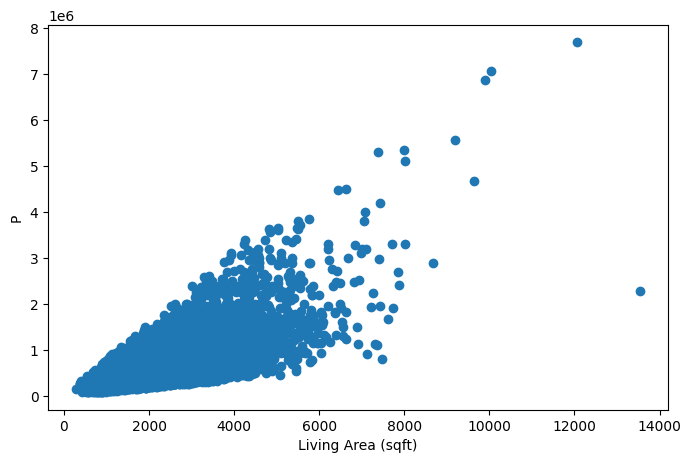

In [63]:
plt.figure(figsize=(8, 5))

plt.scatter(df["sqft_living"], df["price"])
plt.xlabel("Living Area (sqft)")
plt.ylabel("P")

In [64]:
correlation = df["sqft_living"].corr(df["price"])

print("Correlation:", correlation)

Correlation: 0.7020350546118002


In [70]:
X = df[["sqft_living"]]
y = df["price"]


In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [72]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (17290, 1)
Testing features: (4323, 1)
Training target: (17290,)
Testing target: (4323,)


In [73]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [74]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 279.55477931526383
Intercept: -41999.18603993731


In [75]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[ 536679.20714266  768709.67397433 1011922.33197861 1232770.60763767
  670865.50121399  436039.48658916  710003.17031812  461199.41672754
  405288.46086448  212395.66313695]


In [77]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0      365000.0     5.366792e+05
1      865000.0     7.687097e+05
2     1038000.0     1.011922e+06
3     1490000.0     1.232771e+06
4      711000.0     6.708655e+05
5      211000.0     4.360395e+05
6      790000.0     7.100032e+05
7      680000.0     4.611994e+05
8      384500.0     4.052885e+05
9      605000.0     2.123957e+05


In [78]:
mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

MAE: 177867.54034434858


In [79]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("RMSE:", rmse)

RMSE: 276559.1746114674


In [80]:
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.49406905389089006


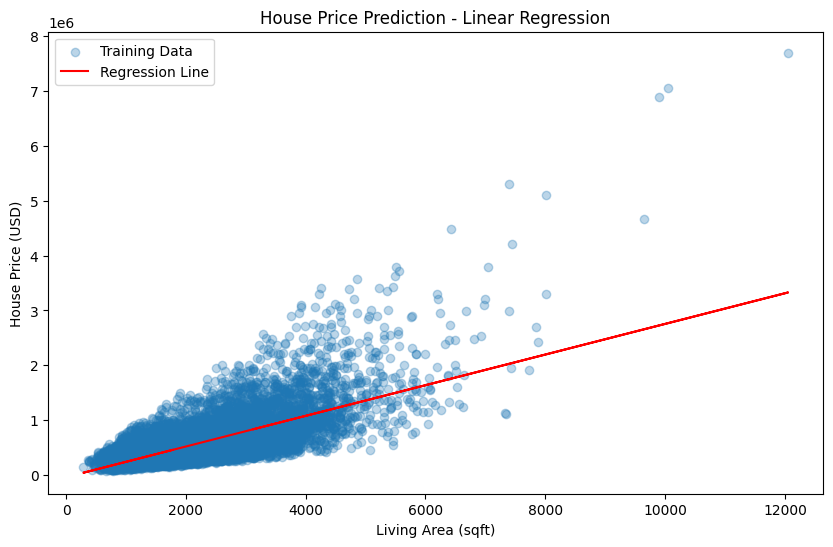

In [81]:
plt.figure(figsize=(10, 6))

# Actual training data
plt.scatter(X_train, y_train, alpha=0.3, label="Training Data")

# Regression line
plt.plot(
    X_train,
    model.predict(X_train),
    color="red",
    label="Regression Line"
)

plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price (USD)")
plt.title("House Price Prediction - Linear Regression")

plt.legend()
plt.show()

In [82]:
new_house = pd.DataFrame({
    "sqft_living": [2000]
})

predicted_price = model.predict(new_house)

print("Predicted House Price: $", predicted_price[0])

Predicted House Price: $ 517110.3725905904
